<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [symphase](https://github.com/Gokaran-Shukla/symphase) · MIT License — any reuse must keep this copyright notice and credit the author.

# SymPhase tutorial 28 — MXenes and 2D materials: structures, convex hulls, phase diagrams

`symphase.twod` builds $M_{n+1}X_nT_2$ MXenes (M = transition metal, X = C/N, T = passivation F, O, OH, Cl, … or none), relaxes them,
and places them in the convex hull of the bulk competing phases. On the command line it **asks** for the elements:

```
$ symphase mxene --hull
  transition metal M (e.g. Cr, Mo, Ti; ordered double-M as outer,inner e.g. Mo,Ti): Cr
  X element (C or N) [C]: C
  n in M(n+1)X(n) (1, 2, 3) [1]: 1
  passivation / termination (F, O, OH, Cl, Br, S, none) [F]: F
  termination site (fcc, hcp, top, auto = lowest energy) [auto]: auto
```
Energies: the universal machine-learned potential **CHGNet** (trained on Materials Project PBE/PBE+U relaxations, MP2020-compatible
energy scale), so elements, carbides, nitrides and fluorides enter one hull. It is a screening tool — confirm with VASP
(`--vasp` writes inputs, `--energies` replaces the model energies by yours).

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import os, json, shutil, tempfile, numpy as np
import matplotlib.pyplot as plt
from symphase import twod
from symphase.twod import (build_mxene, mxene_formula, prompt_mxene, relax_mxene, mxene_hull, load_hull,
                           plot_phase_diagram, find_layers, vacuum_thickness, monolayer_from_bulk, prototype)
from symphase.hull import HullAnalysis, make_entry
MX = "../examples/mxene"

def results(name):
    """shipped results of `symphase mxene --hull` (Cr2CF2, Ni2NF2, Mo2C)"""
    return load_hull(os.path.join(MX, name))

def bulk_formation_energies(name):
    """formation energies (eV/atom) of the relaxed competing phases of one example"""
    lib = json.load(open(os.path.join(MX, name, "library_chgnet.json")))
    ents = {k: make_entry(v["formula"], v["energy"], name=k) for k, v in lib.items()}
    h = HullAnalysis(list(ents.values()))
    return {k: (e.composition.reduced_formula, float(h.form_energy(e)), float(h.e_above_hull(e))) for k, e in ents.items()}

def termination():
    return json.load(open(os.path.join(MX, "termination_F.json")))


## 1. Building MXenes — the questions the code asks, answered from a list here

In [3]:
answers = iter(["Cr", "C", "1", "F", "auto"])
spec = prompt_mxene(inp=lambda q: (lambda a: (print(q + a), a)[1])(next(answers)))   # symphase mxene asks the same questions
print(spec)
for args in (("Cr", "C", 1, "F"), ("Ni", "N", 1, "F"), ("Mo", "C", 1, None), ("Mo,Ti", "C", 2, "O"), ("Ti", "C", 1, "OH")):
    st = build_mxene(*args)
    print(f"{mxene_formula(*args):11s} {st.composition.formula:22s} a0 = {st.lattice.a:.3f} Å, layers {len(find_layers(st))}, vacuum {vacuum_thickness(st):.1f} Å")

MXene builder  M(n+1) X(n) T2   — e.g. Cr + C + F  →  Cr2CF2,   Ni + N + F → Ni2NF2,   Mo + C + none → Mo2C
  transition metal M (e.g. Cr, Mo, Ti; ordered double-M as outer,inner e.g. Mo,Ti): Cr
  X element (C or N) [C]: C
  n in M(n+1)X(n) (1, 2, 3) [1]: 1
  passivation / termination (F, O, OH, Cl, Br, S, none) [F]: F
  termination site (fcc, hcp, top, auto = lowest energy) [auto]: auto
{'M': 'Cr', 'X': 'C', 'n': 1, 'T': 'F', 'site': 'auto'}
Cr2CF2      Cr2 C1 F2              a0 = 3.021 Å, layers 1, vacuum 20.0 Å
Ni2NF2      Ni2 N1 F2              a0 = 2.926 Å, layers 1, vacuum 20.0 Å
Mo2C        Mo2 C1                 a0 = 3.280 Å, layers 1, vacuum 20.0 Å
Mo2TiC2O2   Ti1 Mo2 C2 O2          a0 = 3.343 Å, layers 1, vacuum 20.0 Å
Ti2C(OH)2   Ti2 H2 C1 O2           a0 = 3.469 Å, layers 1, vacuum 20.0 Å


Termination sites: **fcc** (above the metal of the opposite side, 'model I'), **hcp** (above X, 'model II'), **top** (above the outer metal).

## 2. Relax Cr$_2$CF$_2$ on all sites (CHGNet, in-plane cell + positions)

In [4]:
r = relax_mxene("Cr", "C", 1, "F", site="auto")
print("lowest:", r["site"], " a =", round(r["structure"].lattice.a, 3), "Å;  hcp − fcc =",
      round(1000 * (r["sites"]["hcp"] - r["sites"]["fcc"]), 1), "meV/atom")

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on cpu


/usr/local/lib/python3.13/site-packages/chgnet/model/model.py:898: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  volumes = torch.tensor(volumes, dtype=TORCH_DTYPE, device=atomic_numbers.device)


  Cr2CF2     site fcc: E = -7.9139 eV/atom, a = 2.955 Å


CHGNet will run on cpu


  Cr2CF2     site hcp: E = -7.8091 eV/atom, a = 2.761 Å


CHGNet will run on cpu


  Cr2CF2     site top: E = -7.9138 eV/atom, a = 2.949 Å


lowest: fcc  a = 2.955 Å;  hcp − fcc = 104.8 meV/atom


## 3. Convex hull against the bulk Cr–C–F phases (library prototypes, relaxed and cached)

Cr2CF2: E_form = -1.445 eV/atom, E_hull = 265 meV/atom → 0.29 Cr7C3 + 0.11 C + 0.60 CrF2


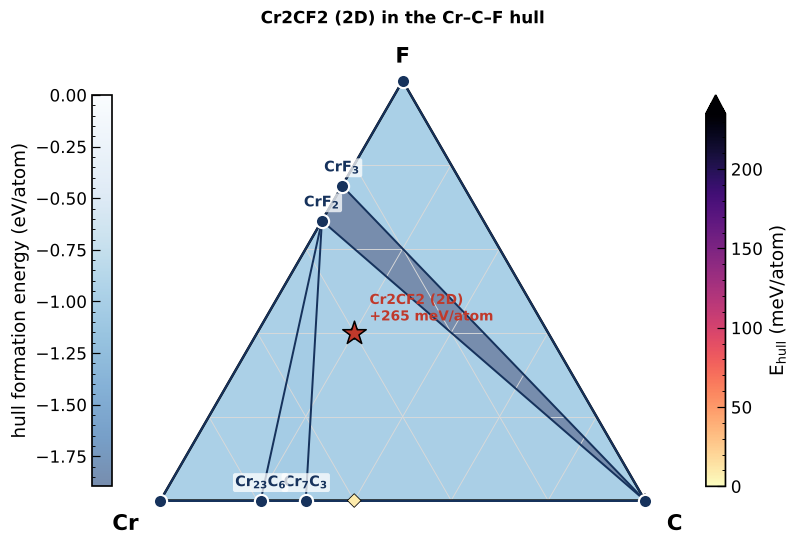

In [5]:
tmp = tempfile.mkdtemp(); cache = os.path.join(tmp, "lib.json")
shutil.copy(os.path.join(MX, "Cr2CF2", "library_chgnet.json"), cache)          # reuse the shipped relaxations
res = mxene_hull({"Cr2CF2": (r["structure"], r["energy"])}, cache=cache, verbose=False)
for row in res["rows"]:
    print(f"{row['label']}: E_form = {row['e_form']:.3f} eV/atom, E_hull = {1000 * row['e_hull']:.0f} meV/atom →",
          " + ".join(f"{v:.2f} {k}" for k, v in row["decomposition"].items()))
plot_phase_diagram(res, title="Cr2CF2 (2D) in the Cr–C–F hull");

## 4. Ni$_2$NF$_2$ and bare Mo$_2$C (shipped results of `symphase mxene --hull`)

Ni2NF2: a = 3.029 Å, E_hull = 377 meV/atom → ['Ni3N', 'N2', 'NiF2']
Mo2C: a = 2.971 Å, E_hull = 391 meV/atom → ['Mo2C']


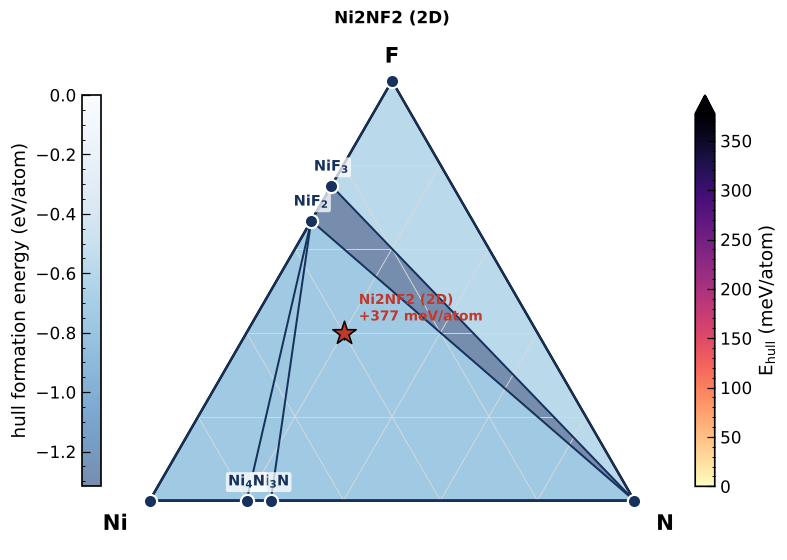

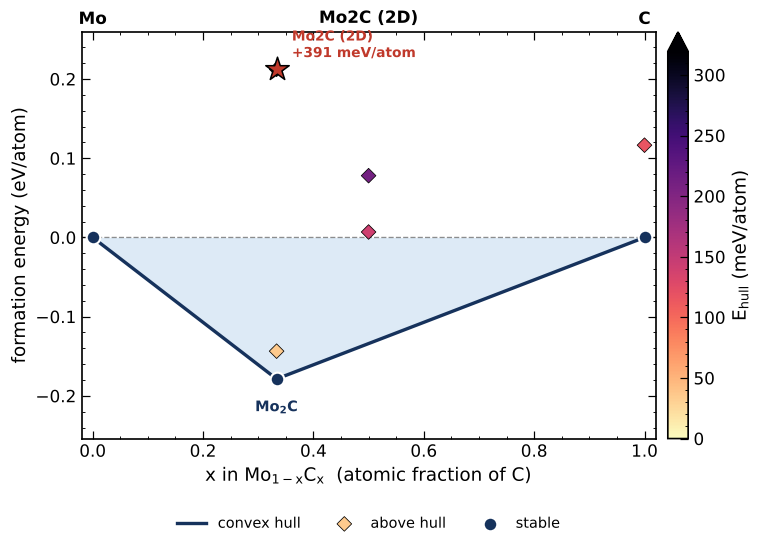

In [6]:
for name in ("Ni2NF2", "Mo2C"):
    rr = results(name); row = rr["rows"][0]
    print(f"{name}: a = {rr['mxene']['a']:.3f} Å, E_hull = {1000 * row['e_hull']:.0f} meV/atom → {list(row['decomposition'])}")
    plot_phase_diagram(rr, title=f"{name} (2D)")

## 5. How good are the bulk energies? Formation energies vs experiment

In [7]:
exp = {"CrF2": -2.688, "CrF3": -3.003, "NiF2": -2.250, "Cr3C2": -0.177, "Cr7C3": -0.167, "Cr23C6": -0.147,
       "Mo2C": -0.159, "MoC": -0.145, "Ni3N": 0.002}
for name in ("Cr2CF2", "Ni2NF2", "Mo2C"):
    for k, (f, ef, eh) in bulk_formation_energies(name).items():
        if f in exp:
            print(f"{k:16s} {f:7s} CHGNet {ef:+.3f}   experiment {exp[f]:+.3f} eV/atom   E_hull {1000 * eh:4.0f} meV/atom")

Cr3C2_D510       Cr3C2   CHGNet -0.163   experiment -0.177 eV/atom   E_hull    9 meV/atom
Cr7C3_D101       Cr7C3   CHGNet -0.201   experiment -0.167 eV/atom   E_hull    0 meV/atom
Cr23C6_D84       Cr23C6  CHGNet -0.166   experiment -0.147 eV/atom   E_hull    0 meV/atom
CrF2_rutile      CrF2    CHGNet -2.754   experiment -2.688 eV/atom   E_hull    0 meV/atom
CrF3_D012        CrF3    CHGNet -2.933   experiment -3.003 eV/atom   E_hull    0 meV/atom
NiF2_rutile      NiF2    CHGNet -2.207   experiment -2.250 eV/atom   E_hull    0 meV/atom
Ni3N_epsFe3N     Ni3N    CHGNet -0.048   experiment +0.002 eV/atom   E_hull    0 meV/atom
Mo2C_beta_Pbcn   Mo2C    CHGNet -0.179   experiment -0.159 eV/atom   E_hull    0 meV/atom
Mo2C_W2C_P-3m1   Mo2C    CHGNet -0.144   experiment -0.159 eV/atom   E_hull   35 meV/atom
MoC_WC           MoC     CHGNet +0.007   experiment -0.145 eV/atom   E_hull  141 meV/atom
MoC_NaCl         MoC     CHGNet +0.078   experiment -0.145 eV/atom   E_hull  212 meV/atom


## 6. Termination phase diagram

$\Delta G_F(\Delta\mu_F)=[E(M_2XF_2)-E(M_2X)-2\mu_F^0-2\Delta\mu_F]/A$: F termination wins for $\Delta\mu_F>\Delta\mu_F^*$.

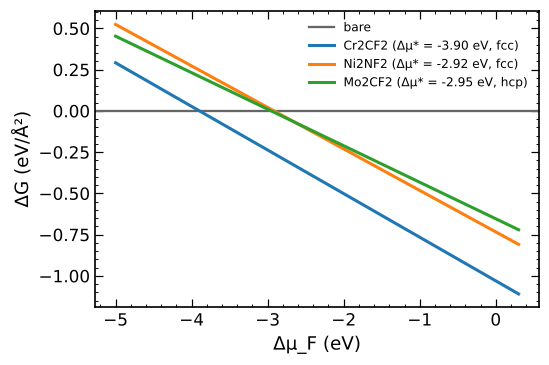

In [8]:
tm = termination()
mus = np.linspace(-5, 0.3, 200)
fig, ax = plt.subplots(figsize=(5.2, 3.5)); ax.axhline(0, color="0.4", label="bare")
for m, d in tm.items():
    ax.plot(mus, (d["dE"] - 2 * mus) / d["area"], lw=2, label=f"{m}F2 (Δμ* = {d['delta_mu_star']:.2f} eV, {d['site']})")
ax.set_xlabel("Δμ_F (eV)"); ax.set_ylabel("ΔG (eV/Å²)"); ax.legend(fontsize=8)

## 7. Generic 2D tools: monolayer from a layered bulk

In [9]:
st = build_mxene("Mo", "C", 1, None, vacuum=3.5); bulk = st.copy(); bulk.make_supercell([1, 1, 2])
print("bulk layers:", len(find_layers(bulk, gap=2.5)))
mono = monolayer_from_bulk(bulk, gap=2.5, vacuum=20)
print("monolayer:", mono.composition.formula, " vacuum", round(vacuum_thickness(mono), 1), "Å")

bulk layers: 2
monolayer: Mo2 C1  vacuum 20.0 Å


## Command line
```bash
symphase mxene                                   # asks for M, X, n, passivation, site
symphase mxene --M Cr --X C --T F --hull --vasp  # Cr2CF2: POSCAR, mxene.json, hull.json, phase_diagram.png, vasp/
symphase mxene --M Ni --X N --T F --hull
symphase mxene --M Mo --X C --T none --hull      # bare Mo2C
symphase mxene --M Mo,Ti --X C --n 2 --T O       # ordered double-M Mo2TiC2O2
symphase mxene ... --hull --energies my_vasp.csv # replace model energies by your DFT (formula/name, eV/atom)
```
Continue with **29_quiz_mxenes_2d.ipynb**.